# V17: transport diagnostics and a failed coverage expansion

**FINAL CPU results: no GPU or new official submission. Retain0.82987/rank23.**
The rank<=19goal remains active. The new15%work/30%row rule fails its frozen
>0.0005incremental-loss gate. E17diagnoses a prior calibration transfer failure
using only cached predictions, fixed existing recipes and tokenization.

Original rows overlap checkpoint training. Later votes are robustness evidence,
not competition CV; their calibration learning/confirmation populations are now
historically inspected. No new temperature, model, mixture or offset was fitted.
The prospective [contract](../docs/SPAN_017_PLAN.md) and
[results](../docs/SPAN_017_RESULTS.md) document scope and limitations.

,population,rows,training_overlap,calibration_fit_population,loss,accuracy,mean_confidence,entropy_nats,ECE10_descriptive,expert_JS,expert_argmax_disagreement
0,original_control,256,True,False,0.599429,0.773438,0.638586,0.806408,0.145822,0.013278,0.167969
1,original_uniform,512,True,False,0.654242,0.750000,0.625733,0.830144,0.126387,0.014044,0.146484
2,later_learning,1024,False,True,1.024173,0.486328,0.524637,0.971321,0.045973,0.008487,0.212891
3,later_confirmation,1024,False,False,1.044265,0.472656,0.526468,0.970556,0.055636,0.007467,0.188477
4,later_v16_matched,1024,False,False,0.997842,0.495117,0.527096,0.968163,0.032492,0.007429,0.190430


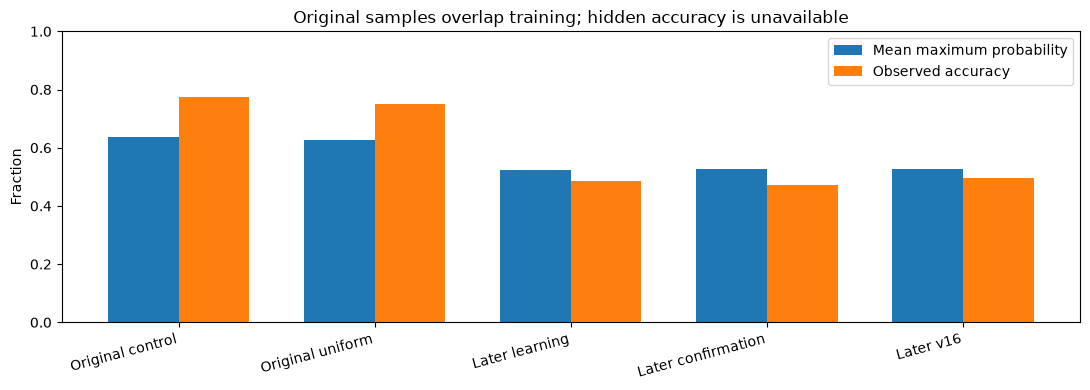

,population,A_fraction,B_fraction,tie_fraction
0,original_control,0.363281,0.347656,0.289062
1,original_uniform,0.330078,0.302734,0.367188
2,later_learning,0.338867,0.361328,0.299805
3,later_confirmation,0.364258,0.342773,0.292969
4,later_v16_matched,0.370117,0.337891,0.291992


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_017'
def read(name):return json.loads((PUB/name).read_text())
e=read('E17_transport.json');h=read('H62_cached_replay.json')
names=list(e['cohorts']);labels=['Original control','Original uniform','Later learning','Later confirmation','Later v16']
rows=[]
for name,c in e['cohorts'].items():
 rows.append({'population':name,'rows':c['rows'],'training_overlap':c['original_labels_seen_in_backbone_training'],
  'calibration_fit_population':c['calibration_fit_population'],'loss':c['base']['log_loss'],
  'accuracy':c['base']['accuracy'],'mean_confidence':c['base']['mean_max_probability'],
  'entropy_nats':c['base']['mean_entropy_nats'],'ECE10_descriptive':c['base']['ECE10_descriptive'],
  'expert_JS':c['expert_disagreement']['mean_JS_nats'],
  'expert_argmax_disagreement':c['expert_disagreement']['argmax_disagreement_fraction']})
table=pd.DataFrame(rows);display(table)
x=np.arange(len(rows));fig,ax=plt.subplots(figsize=(11,4))
ax.bar(x-.18,table['mean_confidence'],.36,label='Mean maximum probability')
ax.bar(x+.18,table['accuracy'],.36,label='Observed accuracy')
ax.set_xticks(x,labels,rotation=15,ha='right');ax.set_ylim(0,1);ax.set_ylabel('Fraction');ax.legend()
ax.set_title('Original samples overlap training; hidden accuracy is unavailable')
fig.tight_layout();plt.show()
display(pd.DataFrame([{'population':name,**dict(zip(['A_fraction','B_fraction','tie_fraction'],c['base']['class_fractions']))}
 for name,c in e['cohorts'].items()]))

Existing frozen temperature: 1.3161518671742531
For equivalent normalized base predictions: L(T)=L(1)/T+mean(log(sum(p**(1/T))))
Historical official losses used:0.83053and0.84797; the routed0.82987recipe is separate.
Official implied term: 0.21694099740995076 ; score-rounding-only interval: [0.216932198456255, 0.21694979636364653]
Assumption: Same scored subset and equivalent base predictions before temperature; clipping/numeric differences are not covered by the rounding interval
This does not recover hidden accuracy, individual labels or a unique probability distribution.


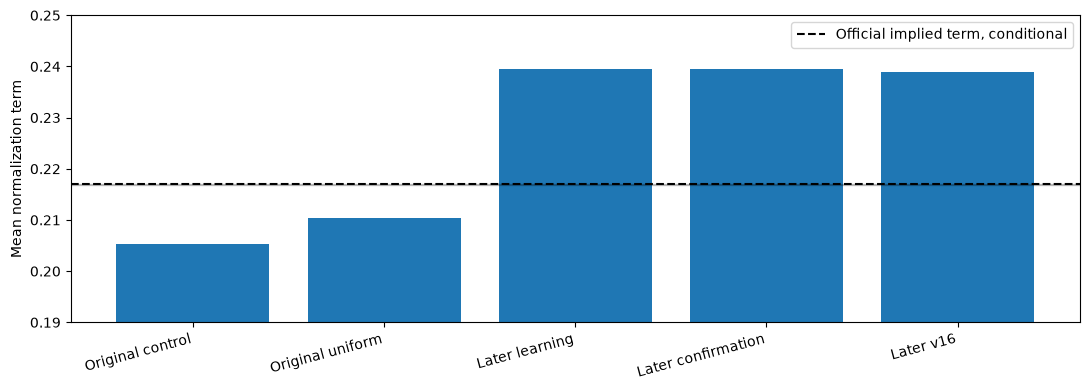

,population,base_loss,fixed_T_loss,scaled_minus_base_loss,calibration_in_sample
0,original_control,0.599429,0.660762,0.061333,False
1,original_uniform,0.654242,0.707523,0.053281,False
2,later_learning,1.024173,1.017632,-0.006541,True
3,later_confirmation,1.044265,1.032851,-0.011414,False
4,later_v16_matched,0.997842,0.997028,-0.000815,False


,population,mean_Gemma_prepared,mean_Llama_prepared,mean_Gemma_full,Gemma_retained_fraction,truncated_rows,multiturn_rows,null_message_rows,prepared_quantiles,CPU_GPU_tokens_identical
0,original_control,940.824219,913.878906,942.914062,0.997784,3,38,0,"[272.0, 523.5, 782.5, 1069.75, 1372.0, 4330.0]",True
1,original_uniform,932.468750,903.845703,946.191406,0.985497,4,77,0,"[271.0, 508.5, 801.0, 1127.5, 1537.9, 4330.0]",True
2,later_learning,949.380859,921.420898,961.618164,0.987274,7,0,0,"[265.0, 520.75, 793.5, 1182.5, 1567.2, 4330.0]",True
3,later_confirmation,945.395508,917.894531,965.818359,0.978854,6,0,0,"[267.0, 525.5, 800.5, 1169.5, 1558.6, 4330.0]",True
4,later_v16_matched,948.870117,918.278320,989.922852,0.958529,7,0,0,"[262.0, 522.75, 802.0, 1154.5, 1546.1, 4330.0]",True


,populations,normalized_prompt_overlap
0,original_control vs original_uniform,1
1,original_control vs later_learning,0
2,original_control vs later_confirmation,1
3,original_control vs later_v16_matched,0
4,original_uniform vs later_learning,1
5,original_uniform vs later_confirmation,0
6,original_uniform vs later_v16_matched,1
7,later_learning vs later_confirmation,0
8,later_learning vs later_v16_matched,0
9,later_confirmation vs later_v16_matched,0


Length matching and similar priors do not prove target calibration transport.
Original predictions are training-overlapping; no replacement temperature is selected.


In [2]:
print('Existing frozen temperature:',e['frozen_temperature'])
print('For equivalent normalized base predictions: L(T)=L(1)/T+mean(log(sum(p**(1/T))))')
term=e['official_score_implied_normalization_term']
print('Historical official losses used:0.83053and0.84797; the routed0.82987recipe is separate.')
print('Official implied term:',term['value'],'; score-rounding-only interval:',term['rounding_only_interval'])
print('Assumption:',term['assumption'])
print('This does not recover hidden accuracy, individual labels or a unique probability distribution.')
values=[e['cohorts'][name]['base']['mean_temperature_normalization_term'] for name in names]
fig,ax=plt.subplots(figsize=(11,4));ax.bar(np.arange(len(names)),values)
ax.axhline(term['value'],color='black',linestyle='--',label='Official implied term, conditional')
ax.axhspan(*term['rounding_only_interval'],color='black',alpha=.2)
ax.set_xticks(range(len(names)),labels,rotation=15,ha='right');ax.set_ylabel('Mean normalization term')
ax.set_ylim(.19,.25);ax.legend();fig.tight_layout();plt.show()
display(pd.DataFrame([{'population':name,'base_loss':c['base']['log_loss'],
 'fixed_T_loss':c['frozen_temperature']['log_loss'],
 'scaled_minus_base_loss':c['frozen_temperature']['log_loss']-c['base']['log_loss'],
 'calibration_in_sample':c['calibration_fit_population']} for name,c in e['cohorts'].items()]))
display(pd.DataFrame([{'population':name,**c['lengths'],
 'CPU_GPU_tokens_identical':c['CPU_GPU_prepared_tokens_identical']} for name,c in e['cohorts'].items()]))
display(pd.DataFrame([{'populations':k,'normalized_prompt_overlap':v} for k,v in e['normalized_prompt_overlaps'].items()]))
print('Length matching and similar priors do not prove target calibration transport.')
print('Original predictions are training-overlapping; no replacement temperature is selected.')

,cohort,rows,parent_selected_rows,H61_selected_rows,candidate_selected_rows,parent_common_cache_log_loss,H61_log_loss,candidate_log_loss,incremental_loss_reduction,descriptive_paired_group95
0,control,256,42,51,63,0.598234,0.598407,0.598690,-0.000456,"[-0.001612, 0.000503]"
1,uniform,512,83,102,120,0.652988,0.652708,0.653049,-0.000061,"[-0.000726, 0.000593]"
2,long,64,6,9,9,0.896484,0.896140,0.896140,0.000344,"[-0.001546, 0.002885]"


,rule,rows,work
0,H60,83,0.099805
1,H61control,102,0.127138
2,H62candidate,120,0.149675


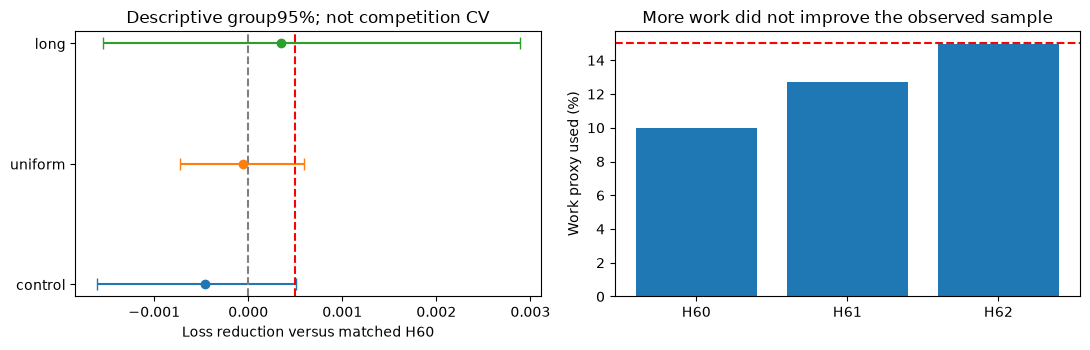

H62decision: Stop H62without GPU; retain0.82987 ; threshold strictly> 0.0005
Full-cache versus actual deployed H60is an unmatched-batch diagnostic, not canonical identity.
New GPU executions:0; new submissions:0; CPU seconds: 23.145479735918343 0.5095465299673378
Global objective remains rank<=19; retain official0.82987.


In [3]:
records=h['coverage'];uniform=records['uniform']
display(pd.DataFrame([{'cohort':name,**r} for name,r in records.items() if name!='test'])[
 ['cohort','rows','parent_selected_rows','H61_selected_rows','candidate_selected_rows',
 'parent_common_cache_log_loss','H61_log_loss','candidate_log_loss',
 'incremental_loss_reduction','descriptive_paired_group95']])
display(pd.DataFrame([{'rule':'H60','rows':uniform['parent_selected_rows'],'work':uniform['parent_work_fraction']},
 {'rule':'H61control','rows':uniform['H61_selected_rows'],'work':uniform['H61_work_fraction']},
 {'rule':'H62candidate','rows':uniform['candidate_selected_rows'],'work':uniform['candidate_work_fraction']}]))
fig,axes=plt.subplots(1,2,figsize=(11,3.6))
cohorts=['control','uniform','long']
for i,name in enumerate(cohorts):
 r=records[name];gain=r['incremental_loss_reduction'];lo,hi=r['descriptive_paired_group95']
 axes[0].errorbar(gain,i,xerr=[[max(0,gain-lo)],[max(0,hi-gain)]],fmt='o',capsize=4)
axes[0].axvline(0,color='gray',linestyle='--');axes[0].axvline(.0005,color='red',linestyle='--')
axes[0].set_yticks(range(3),cohorts);axes[0].set_xlabel('Loss reduction versus matched H60')
axes[0].set_title('Descriptive group95%; not competition CV')
axes[1].bar(['H60','H61','H62'],100*np.array([uniform['parent_work_fraction'],uniform['H61_work_fraction'],uniform['candidate_work_fraction']]))
axes[1].axhline(15,color='red',linestyle='--');axes[1].set_ylabel('Work proxy used (%)')
axes[1].set_title('More work did not improve the observed sample')
fig.tight_layout();plt.show()
assert not h['information_gate_passed'] and e['new_parameter_fits']==0
print('H62decision:',h['decision'],'; threshold strictly>',h['incremental_information_gain_minimum'])
print('Full-cache versus actual deployed H60is an unmatched-batch diagnostic, not canonical identity.')
print('New GPU executions:0; new submissions:0; CPU seconds:',e['elapsed_cpu_seconds'],h['elapsed_cpu_seconds'])
print('Global objective remains rank<=19; retain official0.82987.')